# **Redes Neuronales 2**
## Práctica 1: Introducción a PyTorch, MLP y redes convolucionales

**Temas:**
- Conceptos de PyTorch: tensores, autograd, módulos, datasets y dataloaders.
- Perceptrón simple y perceptrón multicapa (MLP).
- Bucle de entrenamiento completo: clasificación de Iris.
- Clasificación de imágenes (MNIST): MLP vs. red convolucional (CNN).

Los primeros ejercicios repasan los bloques básicos de PyTorch; los últimos construyen la primera red convolucional del curso.

In [2]:
# Imports y configuración básica
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader, random_split

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Usando dispositivo:", device)

Usando dispositivo: cpu


---
## Ejercicio 1: perceptrón simple

Definimos el **perceptrón simple** con activación **sigmoidea** como $\phi(v(\mathbf{x}))=\frac{1}{1+e^{-v(\mathbf{x})}}$, siendo $v(\mathbf{x}) = \mathbf{w}\cdot\mathbf{x}$ la salida lineal, donde $\mathbf{x}=(-1,x_1,\dots,x_m)$ y $\mathbf{w}=(b,w_1,\dots,w_m)$ (llamamos $w_0\equiv b$ para enfatizar su rol de sesgo o _bias_).

- a) Crear una clase `PerceptronSimple` que implemente el forward y un paso de entrenamiento usando **autograd** de PyTorch (gradiente respecto de $\mathbf{w}$), con el error cuadrático medio (MSE) como función de pérdida.
- b) Agregar a la pérdida un término de regularización $L_2$ sobre los pesos ($L_2(\mathbf{w})=\|\mathbf{w}\|_2^2$), ponderado por un parámetro `weight_decay` del constructor.
- c) Crear otra clase `PerceptronSimpleModule`, esta vez heredando de `torch.nn.Module`.


### Este se presenta resuelto como modelo:

In [4]:
### SOLUCIÓN
# a) y b) Perceptrón simple 'a mano' con autograd
class PerceptronSimple:
    def __init__(self, n_entradas, lr=0.1, weight_decay=0.0):
        # w incluye el bias como w[0]; requires_grad para que autograd lo siga
        self.w = torch.randn(n_entradas + 1, requires_grad=True)
        self.lr = lr
        self.weight_decay = weight_decay

    def forward(self, X):
        # agregamos la entrada fija -1 para el bias
        unos = -torch.ones(X.shape[0], 1)
        Xb = torch.cat([unos, X], dim=1)
        v = Xb @ self.w
        return torch.sigmoid(v)

    def paso_entrenamiento(self, X, y):
        y_pred = self.forward(X)
        perdida = ((y_pred - y) ** 2).mean() + self.weight_decay * (self.w ** 2).sum()
        perdida.backward()               # autograd calcula d(perdida)/dw
        with torch.no_grad():
            self.w -= self.lr * self.w.grad   # descenso por el gradiente
            self.w.grad.zero_()
        return perdida.item()

# Probamos con un problema linealmente separable de juguete (OR lógico)
X = torch.tensor([[0.,0.],[0.,1.],[1.,0.],[1.,1.]])
y = torch.tensor([0.,1.,1.,1.])

p = PerceptronSimple(n_entradas=2, lr=0.5, weight_decay=1e-4) # En la unidad 3 vamos a ver de qué se trata el weight decay (por ahora confiar)

for paso in range(500):
    L = p.paso_entrenamiento(X, y)

print(f"pérdida final: {L:.4f}")
print("predicciones:", p.forward(X).detach().numpy().round(2))

pérdida final: 0.0188
predicciones: [0.19 0.88 0.88 1.  ]


In [5]:
### SOLUCIÓN
# c) La misma idea, pero heredando de nn.Module
class PerceptronSimpleModule(nn.Module):
    def __init__(self, n_entradas):
        super().__init__()
        self.lineal = nn.Linear(n_entradas, 1)   # maneja pesos y bias por nosotros

    def forward(self, x):
        return torch.sigmoid(self.lineal.forward(x)).squeeze(-1)

modelo = PerceptronSimpleModule(2)
criterio = nn.MSELoss()

# el weight_decay ahora es un argumento del optimizador (¡equivale a la L2 de arriba!)
opt = torch.optim.SGD(modelo.parameters(), lr=0.5, weight_decay=1e-4)

for paso in range(500):
    opt.zero_grad()
    perdida = criterio(modelo(X), y)
    perdida.backward()
    opt.step()

print(f"pérdida final: {perdida.item():.4f}")
print("predicciones:", modelo(X).detach().numpy().round(2))

pérdida final: 0.0147
predicciones: [0.18 0.89 0.89 1.  ]


nn.linear(in_features, out_features) para y=xW^T + b

 es la capa que implementa una transformacion lineal sobre la entrada.
 Crea yba natruz de oesis W(out_features, in_features)
 y un vector fila de bias

---
## Ejercicio 2: perceptrón multicapa

Implementar un `PerceptronMulticapa` (MLP) con activación **ReLU**, heredando de `torch.nn.Module`. El constructor debe recibir: cantidad de características de entrada, cantidad de neuronas de la (única) capa oculta, y cantidad de salidas. Además, un argumento `salida_sigmoidea` que indique si la salida debe pasar por una sigmoide (para valores en $[0,1]$) o quedar libre. Implementar la ReLU con `nn.ReLU` instanciada (¿cómo sería con `nn.functional.relu`?).

In [6]:
# ====================== COMPLETAR ======================
# ========================================================

class PerceptronMulticapa(nn.Module):

    def __init__(self, n_in, n_hid, n_out, salida_sigmoidea=False):
        super().__init__() #llamamos al constructor de la clase padre

        #vamos a tener dos capas, la oculta y la de salida
        self.oculta = nn.Linear(n_in, n_hid)
        self.salida = nn.Linear(n_hid, n_out)

        #activaciones
        self.relu = nn.ReLU() #me guardo la activacion
        self.sigmoid = nn.Sigmoid()

        self.sigmoidea_flag = salida_sigmoidea
        
        
    def forward(self, x):
        z_hid = self.oculta.forward(x)
        y_hid = self.relu(z_hid) #transformo capa oculta

        z_out = self.salida.forward(y_hid)
        if self.sigmoidea_flag:
            y_out = self.sigmoid(z_out) 
        else:
            y_out = z_out
        return y_out



## Lo probamos con los datos
modelo = PerceptronMulticapa(n_in = 2, n_hid = 4, n_out = 1, salida_sigmoidea = True)
criterio = nn.MSELoss()
opt = torch.optim.SGD(modelo.parameters(), lr = 0.25)

for paso in range(500):
    opt.zero_grad() #reseteamos los gradientes
    salida = modelo(X).squeeze(-1)#ajusta dimension
    perdida = criterio(salida, y) #salida real
    perdida.backward() #calculo los gradientes nuevos
    opt.step()

print(f"pérdida final: {perdida.item():.4f}")
print("predicciones:", modelo(X).squeeze(-1).detach().numpy().round(2))
print("esperado:     ", y.numpy())
    


pérdida final: 0.0037
predicciones: [0.1  0.96 0.95 1.  ]
esperado:      [0. 1. 1. 1.]


In [7]:
#usando functional vaya a saber que es


import torch.nn.functional as F

class PerceptronMulticapa(nn.Module):
    def __init__(self, n_in, n_hid, n_out, salida_sigmoidea=False):
        super().__init__()
        self.oculta = nn.Linear(n_in, n_hid)
        self.salida = nn.Linear(n_hid, n_out)

        self.sigmoidea_flag = salida_sigmoidea

    def forward(self, x):
        z_hid = self.oculta.forward(x)
        y_hid = F.relu(z_hid)

        z_out = self.salida.forward(y_hid)
        if self.sigmoidea_flag:
            y_out = torch.sigmoid(z_out)
        else:
            y_out = z_out
        return y_out


---
## Ejercicio 3: entrenamiento completo sobre Iris

Vamos a entrenar el MLP para clasificar la especie de planta del clásico dataset **Iris** (4 características de la flor, 3 especies). Usaremos `sklearn.datasets.load_iris` para cargar los datos.

- a) Crear una clase `IrisDataset` que herede de `torch.utils.data.Dataset` (métodos `__getitem__` y `__len__`).
- b) Crear particiones de train (60%), validación (20%) y test (20%) con sus respectivos `Dataset` y `DataLoader` (ayuda: `sklearn.model_selection.train_test_split` o `torch.utils.data.random_split`).
- c) Inicializar el MLP del Ejercicio 2 (16 neuronas ocultas, 3 salidas), con `nn.CrossEntropyLoss` y un optimizador `Adam` con `lr=1e-2`.
- d) Escribir y ejecutar el bucle de entrenamiento (bucle externo sobre épocas, interno sobre batches), evaluando en validación en cada época. Graficar las curvas de pérdida de train y validación.
- e) Reportar la exactitud (accuracy) final sobre test.

In [12]:
### Va resuelta la conformación del dataset

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split

# a) Dataset de PyTorch para Iris
class IrisDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)
    def __len__(self):
        return len(self.X)
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

# b) particiones 60/20/20 (estratificadas)
iris = load_iris()

X_tmp, X_test, y_tmp, y_test = train_test_split(iris.data, iris.target,
                                                test_size=0.2, stratify=iris.target,
                                                random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_tmp, y_tmp, test_size=0.25,
                                                  stratify=y_tmp, random_state=SEED)

DF_train = IrisDataset(X_train, y_train)
DF_val= IrisDataset(X_val, y_val)
DF_test = IrisDataset(X_test, y_test)

print(DF_train) #nose ve nada


In [13]:
#acatenemos el DataLoader

train_loader = DataLoader(DF_train, batch_size=16, shuffle=True) #batch para cuando actualizas el gradiente
val_loader   = DataLoader(DF_val, batch_size=64)
test_loader  = DataLoader(DF_test, batch_size=64)
print(f"train: {len(X_train)}, val: {len(X_val)}, test: {len(X_test)}")

train: 90, val: 30, test: 30


In [14]:
# ====================== COMPLETAR ======================
# ========================================================
#inicializar MLP

modelo = PerceptronMulticapa(n_in = DF_train.X.shape[1], n_hid = 4, n_out = len(DF_train.y.unique()) , salida_sigmoidea = False)
criterio = nn.CrossEntropyLoss(reduction = "sum") #no quiero que haga el promedio me da el acumulado
opt = torch.optim.SGD(modelo.parameters(), lr = 0.01)

#ahora entrenamos incluyendo validacion

error_train = []
error_val = []

n_epoch = 50

for epoch in range(n_epoch):
    modelo.train() #modo entrenamiento

    perdida_train_total=0

    for X_batch, y_batch in train_loader:
        opt.zero_grad() #reseteo los gradientes por cada batch
        salida = modelo(X_batch) #calculo la salida
        perdida = criterio(salida, y_batch) #devuelve 
        perdida.backward() #para actualizar los gradientes
        opt.step()
        perdida_train_total += perdida.item() 

    perdida_train_prom = perdida_train_total/len(DF_train)
    error_train.append(perdida_train_prom)

    modelo.eval() #modo evaluacion
    perdida_val_total = 0.0
    correctos = 0

    with torch.no_grad(): #nose para que es esto
        for X_batch, y_batch in val_loader:
            salida = modelo(X_batch)
            perdida = criterio(salida, y_batch) #ojo usa la salida real y la predicha
            perdida_val_total +=perdida.item()

            predicciones = salida.argmax(dim=1)
            correctos += (predicciones ==y_batch).sum().item()

        perdida_val_prom = perdida_val_total / len(DF_val)

        error_val.append(perdida_val_prom)
        accuracy_val = correctos/ len(DF_val)







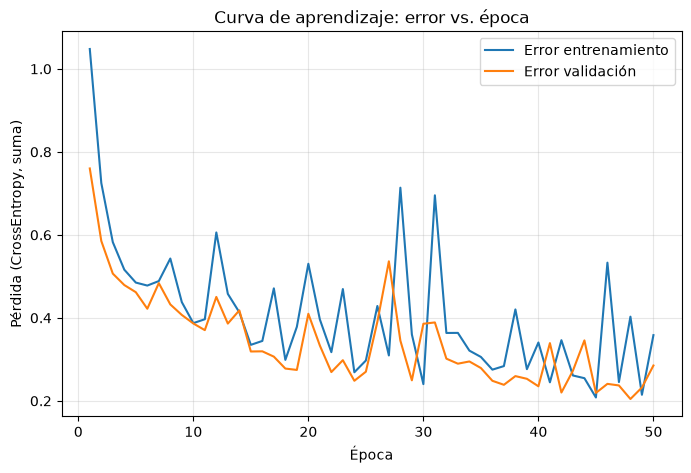

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(range(1, n_epoch + 1), error_train, label="Error entrenamiento")
plt.plot(range(1, n_epoch + 1), error_val, label="Error validación")
plt.xlabel("Época")
plt.ylabel("Pérdida (CrossEntropy, suma)")
plt.title("Curva de aprendizaje: error vs. época")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

---
## Ejercicio 4: clasificación de dígitos con MLP

Pasamos a imágenes: el dataset **MNIST** de dígitos manuscritos de 28×28. Adaptaremos el MLP para clasificar imágenes en 10 categorías:

- Antes de procesar cada imagen hay que **aplanarla** de 28×28 a un vector de 784 componentes (método `view` o `flatten` de los tensores).
- Usar 128 neuronas en la capa oculta y 10 salidas.
- Función de pérdida: **entropía cruzada** (`nn.CrossEntropyLoss`).

- a) Construir los `DataLoader`s de train y test (batch de 128).
- b) Entrenar 3 épocas con Adam (`lr=1e-3`), graficando la pérdida por época. Guardar el modelo con `torch.save`.
- c) Cargar el modelo guardado con `load_state_dict` y calcular las métricas de clasificación sobre test (`sklearn.metrics.classification_report`) y la **matriz de confusión**. ¿Qué dígitos se confunden más?

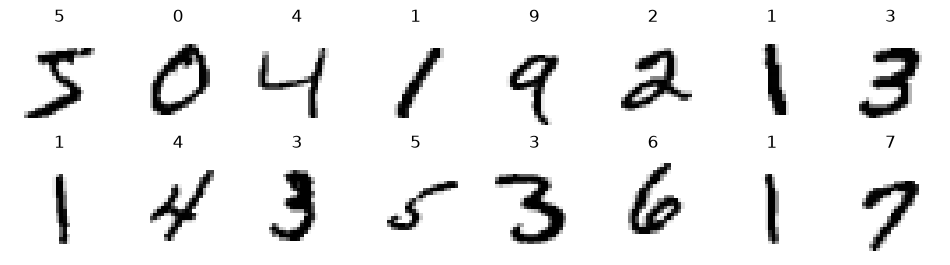

In [19]:
import torchvision
from torchvision import datasets, transforms

mnist_train = datasets.MNIST(root="./data", train=True, download=True,
                             transform=transforms.ToTensor())
mnist_test = datasets.MNIST(root="./data", train=False, download=True,
                            transform=transforms.ToTensor())

# miramos algunos ejemplos
fig, axs = plt.subplots(2, 8, figsize=(12, 3))
for ax, i in zip(axs.ravel(), range(16)):
    ax.imshow(mnist_train[i][0].squeeze(), cmap="gray_r")
    ax.set_title(mnist_train[i][1]); ax.axis("off")
plt.show()

In [20]:
# ====================== COMPLETAR ======================
# ========================================================

#primero construimos los datasets

class Minst_Dataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)

    def __len__(self):
        return len(self.X)
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

from sklearn.model_selection import train_test_split

X_tmp = mnist_train.data.numpy()      # shape: (60000, 28, 28), uint8
y_tmp = mnist_train.targets.numpy()   # shape: (60000,)

X_test = mnist_test.data.numpy()      # shape: (10000, 28, 28)
y_test = mnist_test.targets.numpy()   # shape: (10000,)

def preparar(X):
    X = X.reshape(X.shape[0], -1).astype("float32")  # aplano: (N, 28, 28) -> (N, 784)
    return X / 255.0                                    # normalizo a [0, 1]

X_tmp  = preparar(X_tmp)    # (60000, 784)
X_test = preparar(X_test)   # (10000, 784)


X_train, X_val, y_train, y_val = train_test_split(
    X_tmp, y_tmp, test_size=0.2, stratify=y_tmp, random_state=SEED
) #balanceo por clase


DF_train = Minst_Dataset(X_train, y_train)
DF_val   = Minst_Dataset(X_val, y_val)
DF_test  = Minst_Dataset(X_test, y_test)

train_loader = DataLoader(DF_train, batch_size=128, shuffle=True)
val_loader   = DataLoader(DF_val, batch_size=128)
test_loader  = DataLoader(DF_test, batch_size=128)

In [21]:
# ====================== COMPLETAR ======================
# ========================================================

modelo = PerceptronMulticapa(n_in = DF_train.X.shape[1], n_hid = 128, n_out = len(DF_train.y.unique()) , salida_sigmoidea = False)
criterio = nn.CrossEntropyLoss(reduction = "sum") #no quiero que haga el promedio me da el acumulado
opt = torch.optim.SGD(modelo.parameters(), lr = 0.01)

#ahora entrenamos incluyendo validacion

error_train = []
error_val = []

n_epoch = 50

for epoch in range(n_epoch):
    modelo.train() #modo entrenamiento

    perdida_train_total=0

    for X_batch, y_batch in train_loader:
        opt.zero_grad() #reseteo los gradientes por cada batch
        salida = modelo(X_batch) #calculo la salida
        perdida = criterio(salida, y_batch) #devuelve 
        perdida.backward() #para actualizar los gradientes
        opt.step()
        perdida_train_total += perdida.item() 

    perdida_train_prom = perdida_train_total/len(DF_train)
    error_train.append(perdida_train_prom)

    modelo.eval() #modo evaluacion
    perdida_val_total = 0.0
    correctos = 0

    with torch.no_grad(): #nose para que es esto
        for X_batch, y_batch in val_loader:
            salida = modelo(X_batch)
            perdida = criterio(salida, y_batch) #ojo usa la salida real y la predicha
            perdida_val_total +=perdida.item()

            predicciones = salida.argmax(dim=1)
            correctos += (predicciones ==y_batch).sum().item()

        perdida_val_prom = perdida_val_total / len(DF_val)

        error_val.append(perdida_val_prom)
        accuracy_val = correctos/ len(DF_val)







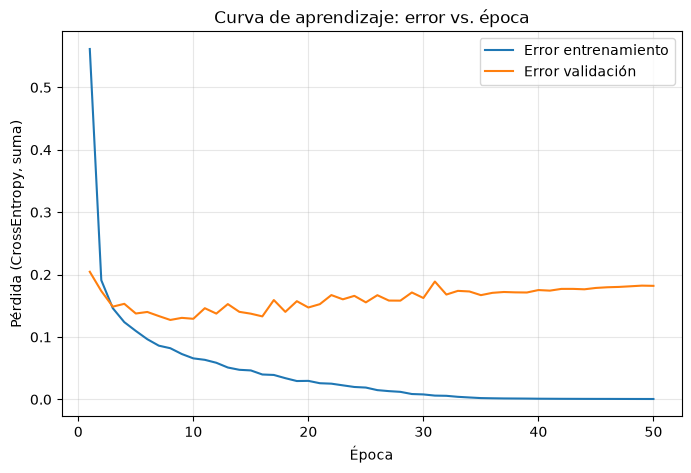

In [22]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(range(1, n_epoch + 1), error_train, label="Error entrenamiento")
plt.plot(range(1, n_epoch + 1), error_val, label="Error validación")
plt.xlabel("Época")
plt.ylabel("Pérdida (CrossEntropy, suma)")
plt.title("Curva de aprendizaje: error vs. época")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

---
## Ejercicio 5: red neuronal convolucional

Definir un modelo `NetCNN` con un "cabezal" tipo MLP y la siguiente estructura:
* Capa convolucional (6 mapas de salida, kernel 5×5) + ReLU
* Max pooling 2×2
* Capa convolucional (16 mapas de salida, kernel 5×5) + ReLU
* Max pooling 2×2
* Capa totalmente conectada ($n$ entradas → 120) + ReLU
* Capa totalmente conectada (→ 84) + ReLU
* Capa de salida (→ 10)

Calcular el tamaño de los _feature maps_ a medida que fluyen por la red para encontrar $n$. Recordar que, con $F$ el tamaño del filtro, $W$ el de la entrada, $P$ el padding y $S$ el stride, la salida de una convolución tiene tamaño $O = \frac{W - F + 2P}{S} + 1$.

Luego entrenar como en el Ejercicio 4 y comparar métricas con el MLP.

Hay que usar nn.Conv2d y nn.MaxPool2d

In [ ]:
# ====================== COMPLETAR ======================
# ========================================================
class NetCNN(nn.Module):
    def __init__(self, n_out=10):
        #aca hay que definir los bloques

        super().__init__()

        # 1 entrada y sacas 6 imagenes
        self.conv1 = nn.Conv2d(in_channels = 1, out_channels = 6, kernel_size = 5)
        self.pool1 = nn.MaxPool2d(kernel_size =2)

        # 6 entradas y despues 16 salidas
        self.conv2 = nn.Conv2d(in_channels=6, out_channels=16, kernel_size=5)
        self.pool2 = nn.MaxPool2d(kernel_size=2)

        #activacion
        self.relu = nn.ReLU()

        n= 4*4*16 #la ultima capa es 16 matrices 4x4

        self.fc1 = nn.Linear(n, 120)
        self.fc2 = nn.Linear(120,84)
        self.fc3 = nn.Linear(84,n_out)

    def forward(self,x):
        x = self.conv1(x)
        x = self.relu(x) #hay que romper linealidad
        x = self.pool1(x)

        x = self.conv2(x)
        x = self.relu(x)
        x = self.pool2(x)

        x = x.flatten(start_dim=1)   # (batch, 16, 4, 4) -> (batch, 256)

        x = self.fc1(x)
        x = self.relu(x)
        x = self.fc2(x)
        x = self.relu(x)
        x = self.fc3(x)


        return x



In [ ]:
modelo_cnn = NetCNN(n_out = 10)
criterio = nn.CrossEntropyLoss()
opt = torch.optim.SGD(modelo_cnn.parameters(), lr = 0.01)

error_train = []
error_val = []

n_epoch = 15

for epoch in range(n_epoch):
    modelo_cnn.train() #hay que aclarar que vamos a entrenar
    perdida_train_total = 0.0
    